In [ ]:
!pip install rdkit
!pip install tensorflow

In [ ]:

import sys
import os
import pandas as pd
import numpy as np
import json
from sklearn.model_selection import train_test_split
import random as rn
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, Concatenate
from tensorflow.keras.initializers import RandomNormal
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow import keras
from tensorflow.keras.callbacks import ReduceLROnPlateau, ModelCheckpoint, TensorBoard
from tensorflow.keras.utils import Sequence

from rdkit import Chem
from rdkit.Chem import Draw, Descriptors
%matplotlib inline

%tensorflow_version 2.x
import tensorflow as tf

In [ ]:
seed = 23
np.random.seed(seed)
rn.seed(seed)

In [ ]:

csv_path = keras.utils.get_file(
    "HIV7.csv", "https://raw.githubusercontent.com/McahitKutsal/hivcsv/main/HIV7.csv"
)


df = pd.read_csv(csv_path)

df['smiles'] = df['smiles'].astype('str')
mask = (df['HIV_active']==1)
df = df.loc[mask]
mask = (df['smiles'].str.len() < 128)
df = df.loc[mask]
smiles = df['smiles']
data = df['smiles']
full_train, test = train_test_split(data, test_size=0.2, random_state=seed)
len(data)

In [ ]:
val_split = 0.10
train, val_set = train_test_split(full_train, test_size=val_split, random_state=seed)

In [ ]:
char_to_int = {'n': 0, '[': 1, '\\': 2, 'E': 3, 'H': 4, ')': 5, 'B': 6, '9': 7, '2': 8, ']': 9, '7': 10, '!': 11, 't': 12, 's': 13, 'o': 14, 'c': 15, 'K': 16, '-': 17, '/': 18, 'l': 19, 'A': 20, 'r': 21, '@': 22, 'C': 23, '=': 24, '6': 25, 'N': 26, 'L': 27, 'a': 28, '5': 29, 'S': 30, 'T': 31, '#': 32, '+': 33, 'P': 34, 'i': 35, '(': 36, '8': 37, '1': 38, 'I': 39, 'e': 40, 'O': 41, '3': 42, 'F': 43, '4': 44, '.': 45, 'Z': 46, 'b': 47, 'G': 48, 'd': 49, 'g': 50, 'M': 51, 'U': 52, 'u': 53, 'X':54, '$':55, 'R':56, 'h':57, '%':58, '0':59}
int_to_char = {'0': 'n', '1': '[', '2': '\\', '3': 'E', '4': 'H', '5': ')', '6': 'B', '7': '9', '8': '2', '9': ']', '10': '7', '11': '!', '12': 't', '13': 's', '14': 'o', '15': 'c', '16': 'K', '17': '-', '18': '/', '19': 'l', '20': 'A', '21': 'r', '22': '@', '23': 'C', '24': '=', '25': '6', '26': 'N', '27': 'L', '28': 'a', '29': '5', '30': 'S', '31': 'T', '32': '#', '33': '+', '34': 'P', '35': 'i', '36': '(', '37': '8', '38': '1', '39': 'I', '40': 'e', '41': 'O', '42': '3', '43': 'F', '44': '4', '45': '.', '46': 'Z', '47': 'b', '48': 'G', '49': 'd', '50': 'g', '51': 'M', '52': 'U', '53': 'u', '54':'X', '55':'$', '56':'R', '57':'h', '58':'%', '59':'0'}
n_vocab = len(char_to_int)

In [ ]:

def vectorize(smiles, embed, n_vocab):
    one_hot = np.zeros((smiles.shape[0], embed, n_vocab), dtype=np.int8)
    for i, smile in enumerate(smiles):
        one_hot[i,0,char_to_int["$"]] = 1
        for j, c in enumerate(smile):
            one_hot[i,j+1,char_to_int[c]] = 1
        one_hot[i,len(smile)+1:,char_to_int["X"]] = 1
    return one_hot[:,0:-1,:], one_hot[:,1:,:]

In [ ]:

embed = 128
X_train, y_train = vectorize(train, embed, n_vocab)
X_val, y_val = vectorize(val_set, embed, n_vocab)
X_test, y_test = vectorize(test, embed, n_vocab)

In [ ]:

enc_input = Input(shape=(X_train.shape[1:]))
output, state_h, state_c = LSTM(96, return_state=True)(enc_input)
states = Concatenate(axis=-1)([state_h, state_c])



sh = Dense(48, activation='relu')(state_h)
sc = Dense(48, activation='relu')(state_c)


state_h_decoded = Dense(96, activation='relu')(sh)
state_c_decoded = Dense(96, activation='relu')(sc)
encoder_states = [state_h_decoded, state_c_decoded]
dec_input = Input(shape=(X_train.shape[1:]))
dec1 = LSTM(96, return_sequences=True)(dec_input, initial_state=encoder_states)
output = Dense(y_train.shape[2], activation='softmax')(dec1)

model = Model(inputs=[enc_input, dec_input], outputs=output)


In [ ]:
X_train.shape[1:]

(127, 60)

In [ ]:
import keras.backend as K
def f1(y_true, y_pred):
    true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
    possible_positives = K.sum(K.round(K.clip(y_true, 0, 1)))
    predicted_positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
    precision = true_positives / (predicted_positives + K.epsilon())
    recall = true_positives / (possible_positives + K.epsilon())
    f1_val = 2*(precision*recall)/(precision+recall+K.epsilon())
    return f1_val

def sensitivity(y_true, y_pred):
    true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
    possible_positives = K.sum(K.round(K.clip(y_true, 0, 1)))
    return true_positives / (possible_positives + K.epsilon())

def specificity(y_true, y_pred):
    true_negatives = K.sum(K.round(K.clip((1-y_true) * (1-y_pred), 0, 1)))
    possible_negatives = K.sum(K.round(K.clip(1-y_true, 0, 1)))
    return true_negatives / (possible_negatives + K.epsilon())

def recall(y_true, y_pred):
        """Recall metric.

        Only computes a batch-wise average of recall.

        Computes the recall, a metric for multi-label classification of
        how many relevant items are selected.
        """
        true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        possible_positives = K.sum(K.round(K.clip(y_true, 0, 1)))
        recall = true_positives / (possible_positives + K.epsilon())
        return recall

def npv(y_actual, y_pred):

    negative_value = 1.

    if y_pred.shape[-1]==2: 
        y_actual = tf.cast(tf.argmax(y_actual, -1), tf.float32) 
        y_pred = tf.cast(tf.argmax(y_pred, -1), tf.float32) 

    else: 
        y_pred = tf.round(y_pred) 

    
    tn = tf.reduce_sum(tf.cast(tf.logical_and(tf.equal(y_pred, negative_value),
                                              tf.equal(y_pred, y_actual)), tf.float32))
    
    fn = tf.reduce_sum(tf.cast(tf.logical_and(tf.equal(y_pred, negative_value),
                                              tf.not_equal(y_pred, y_actual)), tf.float32))

    result = tn / ((tn + fn) + K.epsilon()) 
    return result

from sklearn.metrics import roc_auc_score
from keras.callbacks import Callback
class RocCallback(Callback):
    def __init__(self,training_data,validation_data):
        self.x = training_data[0]
        self.y = training_data[1]
        self.x_val = validation_data[0]
        self.y_val = validation_data[1]


    def on_train_begin(self, logs={}):
        return

    def on_train_end(self, logs={}):
        return

    def on_epoch_begin(self, epoch, logs={}):
        return

    def on_epoch_end(self, epoch, logs={}):
        y_pred_train = self.model.predict_on_batch(self.x)
        roc_train = roc_auc_score(self.y, y_pred_train)
        y_pred_val = self.model.predict_on_batch(self.x_val)
        roc_val = roc_auc_score(self.y_val, y_pred_val)
        print('\rroc-auc_train: %s - roc-auc_val: %s' % (str(round(roc_train,4)),str(round(roc_val,4))),end=100*' '+'\n')
        return

    def on_batch_begin(self, batch, logs={}):
        return

    def on_batch_end(self, batch, logs={}):
        return

roc = RocCallback(training_data=(X_train, y_train),
                  validation_data=(X_test, y_test))

In [ ]:

batch_size = 16
steps_per_epoch = len(X_train) // batch_size
model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['acc', f1, recall, keras.metrics.Precision(),npv])

In [ ]:

class Data_Generator(Sequence):
    def __init__(self, input_data, labels, batch_size):
        self.input_data, self.labels = input_data, labels
        self.batch_size = batch_size

    def __len__(self):
        return int(np.ceil(len(self.input_data) / float(self.batch_size)))

    def __getitem__(self, idx):
        x = self.input_data[idx * self.batch_size:(idx + 1) * self.batch_size]
        y = self.labels[idx * self.batch_size:(idx + 1) * self.batch_size]

        batch_x, batch_y = np.array(x), np.array(y)

        return [batch_x, batch_x], batch_y

In [ ]:
training_generator = Data_Generator(X_train, y_train, batch_size)
validation_generator = Data_Generator(X_val, y_val, batch_size)

In [ ]:
keras.utils.plot_model(
    model,
    show_shapes=True,
    show_dtype=True,
    show_layer_names=True,
)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping   

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",      
    patience=12,            
    mode="min",              
    restore_best_weights=True,
    verbose=1
)


In [ ]:
from tensorflow.keras.utils import Sequence

class Data_Generator(Sequence):
    def __init__(self, input_data, labels, batch_size, **kwargs):
        super().__init__(**kwargs)             
        self.input_data, self.labels = input_data, labels
        self.batch_size = batch_size

    def __len__(self):
        return int(np.ceil(len(self.input_data) / self.batch_size))

    def __getitem__(self, idx):
        x = self.input_data[idx * self.batch_size:(idx + 1) * self.batch_size]
        y = self.labels[idx * self.batch_size:(idx + 1) * self.batch_size]

        batch_x, batch_y = np.array(x), np.array(y)

       
        return (batch_x, batch_x), batch_y     


In [ ]:
training_generator = Data_Generator(X_train, y_train, batch_size)
validation_generator = Data_Generator(X_val, y_val, batch_size)

In [ ]:

validation_steps = len(validation_generator)

history = model.fit(
    training_generator,
    steps_per_epoch=steps_per_epoch,
    epochs=250,
    validation_data=validation_generator,
    validation_steps=validation_steps,
    shuffle=True,
    callbacks=[roc, early_stop]
)



In [ ]:

fig, (axis1, axis2) = plt.subplots(nrows=1, ncols=2, figsize=(16,6))

axis1.plot(history.history["acc"], label='Train', linewidth=3)
axis1.plot(history.history["val_acc"], label='Validation', linewidth=3)
axis1.set_title('Model accuracy', fontsize=16, color="white")
axis1.set_ylabel('accuracy')
axis1.set_xlabel('epoch')
axis1.legend(loc='lower right')

axis2.plot(history.history["loss"], label='Train', linewidth=3)
axis2.plot(history.history["val_loss"], label='Validation', linewidth=3)
axis2.set_title('Model loss', fontsize=16, color="white")
axis2.set_ylabel('loss')
axis2.set_xlabel('epoch')
axis2.legend(loc='upper right')
plt.show()

In [ ]:
encoder_model = Model(inputs=model.layers[0].input, outputs=model.layers[3].output)

In [ ]:


latent_input = Input(shape=(48, ))
state_h = model.layers[5](latent_input)
state_c = model.layers[6](latent_input)
latent_to_states_model = Model(latent_input, [state_h, state_c])

In [ ]:

decoder_inputs = Input(batch_shape=(1, 1, 60))
decoder_lstm = LSTM(96, return_sequences=True, stateful=True)(decoder_inputs)
decoder_outputs = Dense(60, activation='softmax')(decoder_lstm)
gen_model = Model(decoder_inputs, decoder_outputs)
for i in range(1,3):
    gen_model.layers[i].set_weights(model.layers[i+6].get_weights())

In [ ]:

def sample_with_temp(preds, sampling_temp):
    streched = np.log(preds) / sampling_temp
    streched_probs = np.exp(streched) / np.sum(np.exp(streched))
    return np.random.choice(range(len(streched)), p=streched_probs)

In [ ]:

def sample_smiles(latent, n_vocab, sampling_temp):
    states = latent_to_states_model.predict(latent)
    gen_model.layers[1].reset_states(states=[states[0], states[1]])

    startidx = char_to_int["$"]
    samplevec = np.zeros((1,1,n_vocab))
    samplevec[0,0,startidx] = 1
    sequence = ""

    for i in range(101):
        preds = gen_model.predict(samplevec)[0][-1]
        if sampling_temp == 1.0:
          sampleidx = np.argmax(preds)
        else:
          sampleidx = sample_with_temp(preds, sampling_temp)
        samplechar = int_to_char[str(sampleidx)]
        if samplechar != "X":
            sequence += samplechar
            samplevec = np.zeros((1,1,n_vocab))
            samplevec[0,0,sampleidx] = 1
        else:
            break
    return sequence

In [ ]:

def generate(latent_seed, sampling_temp, scale, quant):
  samples, mols = [], []
  i = 0
  while i < quant:
    latent_vec = latent_seed + scale*(np.random.randn(latent_seed.shape[1]))
    out = sample_smiles(latent_vec, n_vocab, sampling_temp)
    mol = Chem.MolFromSmiles(out)
    print(out, mol, i)
    if mol:

      try:
        RotBonds = Chem.Descriptors.NumRotatableBonds(mol)
        PSA = Chem.Descriptors.TPSA(mol)
        hDonorNum = Chem.Lipinski.NumHDonors(mol)
        hAcceptorNum = Chem.Lipinski.NumHAcceptors(mol)
        logp = Descriptors.MolLogP(mol)
        mol_weight = Descriptors.MolWt(mol)
        print(f'donor: {hDonorNum}, acceptor: {hAcceptorNum}, logp: {logp}, molweight: {mol_weight}')
        if hDonorNum <=5 and hAcceptorNum <= 10 and mol_weight <500 and logp <=5 and PSA <= 140 and RotBonds <= 10:
          i +=1
          mols.append(mol)
          samples.append(out)
      except:
        print('başaramadık')
  return mols, samples

In [ ]:
latent_space = encoder_model.predict(X_train)
latent_seed = latent_space[50:51]
sampling_temp = 0.75
scale = 0.5
quantity = 50
t_mols, t_smiles = generate(latent_seed, sampling_temp, scale, quantity)


In [ ]:
Draw.MolsToGridImage(t_mols, molsPerRow=3, subImgSize=(400, 400))

In [ ]:
for i in t_smiles:
  print(i)

Cc1cc(Nc2ccccc2)n(COC(=O)c2ccccc2)c(=O)n1
COc1ccc(OC2CCC(C)C(COC(=O)O)c2)c(=O)[nH]1
Cc1cc(C(=O)CC2CCC(CO)O2)c(O)c(=O)[nH]c1=O
Cc1cc(C=Cc2c(O)c(O)cc(C(=O)O)cc12)C(=O)O
Cc1cc(-c2ccc(O)c(C(=O)O)c2)cc2ccccc2c1=O
Cc1c(O)cccc(S(=O)(=O)c2ccccc2o1)CCC(C)F
Cc1cc(C(=O)C2=CC3C(=O)C3=CCC2)c(=O)[nH]c1
Cc1cc(C(=O)C2=NCCCC(C)C(=O)c2)c(Cl)c(O)c1
COc1cc(C(=O)Cc2ccc(OC)c(C(=O)O)c2)ccc1C
Cc1cc(N)cc(C(=O)NN=Cc2ccccc2)cc2ccccc21.[NaH]
COc1cc(C(=O)C(=O)C(=O)c2ccccc2)c(C)cc1Cl
Cc1cc(NC(=O)c2cn(C)cc2)cc(Cl)c1S(=O)(=O)O
Cc1cc(O)ccc1N=Nc1cc(O)c(C(=O)O)c2ccccc12
C1n2ccccc2c1C(=O)Nc1ccc(C=Nc2ccccc2)cc1
C[n+]1c(-c2ccccc2)c(S)c1C(=O)NC(=O)CCCCl
Cc1cc(N=Nc2ccc(C(=O)NC(=O)O)cc2)ccc1Cl
Cc1cc(OCc2ccc(Cl)cc2)[n+]1CCC(O)C(=O)OC.[NaH]
Cc1cc(NC(=O)c2ccc(C#N)c(S)c2c1OC)C(=O)O
COc1ccc(-c2cc(F)c(Cl)cc2C(=O)CCC1)SC(C)=O
Cc1c(O)cccc1S(=O)(=O)c1ccc(Cl)c(Cl)c1O
Cn1c(F)ccccc1C(=O)Nc1ccc(O)cc1S(=O)(=O)O
Cc1c(O)cccc1S(=O)(=O)c1ccc(C=Cc2ccccc2)N1
Cc1cc(O)cc(NC(=O)NC(=O)Nc2ccccc2)ccc1O
C=C(O)c1cc(Cl)cc(O)c1C(=O)N1CCCCC2CCCC12
Cc1cc(C(

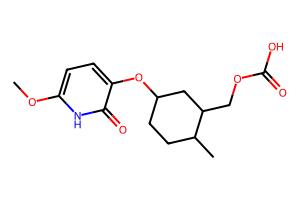

In [ ]:
Draw.MolsToGridImage([t_mols[1]], molsPerRow=1, subImgSize=(300, 200))